# 02 - Modeling

Models trained by `scripts/train.py` (`python -m scripts.train`):
- **DecisionTree** and **RandomForest** (from the lectures) and **XGBoost** (new model).
- Target `is_outperform_20d`: the stock beats its country ETF (in USD) over the next 20 trading days.
- Temporal split with a 20-day embargo: train 2005-2018, validation 2019-2021, test 2022-2026.
- Hyperparameter tuning on the validation period (ROC AUC); the best configuration of each family is
  refitted on train + validation and evaluated once on test.

This notebook reads the saved results (`output/tuning_results.csv`, `data/processed/predictions.parquet`,
`data/models/models.joblib`) instead of training again.

In [1]:
import sys
sys.path.insert(0, "..")
import json

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.metrics import roc_auc_score

import config as cfg
from scripts.train import TARGET, precision_at_top

pd.set_option("display.width", 160)
sns.set_theme(style="whitegrid")
IMG = cfg.ROOT / "images"

tuning = pd.read_csv(cfg.OUTPUT_DIR / "tuning_results.csv")
pred = pd.read_parquet(cfg.PROCESSED_DIR / "predictions.parquet")
bundle = joblib.load(cfg.MODELS_DIR / "models.joblib")
PREDS = [c for c in pred.columns if c.startswith("pred_")]
print(pred["split"].value_counts())

split
test          230919
validation    115887
live            4252
Name: count, dtype: int64


## 1. Hyperparameter tuning (validation 2019-2021)

In [2]:
tuning.sort_values(["family", "auc_val"], ascending=[True, False]).round(4)

,family,params,auc_val,precision_val_p50,precision_val_top10,seconds
7,dt,"{""max_depth"": 8, ""min_samples_leaf"": 500}",0.5258,0.5031,0.5029,26
5,dt,"{""max_depth"": 6, ""min_samples_leaf"": 500}",0.5255,0.5114,0.5168,26
3,dt,"{""max_depth"": 4, ""min_samples_leaf"": 500}",0.5232,0.5076,0.4898,17
8,dt,"{""max_depth"": 8, ""min_samples_leaf"": 3000}",0.5208,0.4956,0.4955,24
4,dt,"{""max_depth"": 4, ""min_samples_leaf"": 3000}",0.5208,0.5076,0.4922,19
6,dt,"{""max_depth"": 6, ""min_samples_leaf"": 3000}",0.5189,0.4990,0.5003,22
2,feature_set,"{""feature_set"": ""stock_only"", ""n"": 107}",0.5323,0.5058,0.5166,0
1,feature_set,"{""feature_set"": ""no_market_macro"", ""n"": 190}",0.5260,0.5008,0.5065,0
0,feature_set,"{""feature_set"": ""all"", ""n"": 251}",0.5148,0.4925,0.5061,0
11,rf,"{""max_depth"": 14, ""max_features"": ""sqrt"", ""n_e...",0.5375,0.5068,0.5240,44


In [3]:
bundle["params"], bundle["feature_set"]

({'dt': {'max_depth': 8, 'min_samples_leaf': 500},
  'rf': {'max_depth': 14,
   'max_features': 'sqrt',
   'n_estimators': 150,
   'min_samples_leaf': 200,
   'max_samples': 0.3},
  'xgb': {'max_depth': 3,
   'learning_rate': 0.03,
   'n_estimators': 234,
   'subsample': 0.7,
   'colsample_bytree': 0.6,
   'min_child_weight': 50}},
 'stock_only')

**Feature set selection (step 1):** with the same XGBoost, using only stock-level features (107: growth,
technical, TA-Lib, relative strength, cross-sectional ranks and stock dummies) gives a higher validation AUC
(0.532) than adding the market-wide and macro features (all 251: 0.515). Those features are identical for every
stock of a day, so the trees use them to memorise periods of the training years, which does not generalise.
They are still useful as **trading filters** (market regime) and in the EDA, but not as model inputs.

## 2. Out-of-sample scores

In [4]:
scores = pd.read_csv(cfg.OUTPUT_DIR / "model_scores.csv")
scores.round(4)

,split,model,auc,precision_p50,precision_top10,base_rate
0,validation,pred_dt,0.5258,0.5031,0.5029,0.4852
1,validation,pred_rf,0.5375,0.5068,0.5240,0.4852
2,validation,pred_xgb,0.5395,0.5102,0.5163,0.4852
3,validation,pred_ensemble,0.5348,0.5090,0.5210,0.4852
4,test,pred_dt,0.5112,0.4889,0.4848,0.4810
5,test,pred_rf,0.5309,0.5041,0.5420,0.4810
6,test,pred_xgb,0.5243,0.5034,0.5128,0.4810
7,test,pred_ensemble,0.5213,0.4981,0.5194,0.4810


AUCs of 0.51-0.54 look small, but this is a cross-sectional ranking problem with very noisy labels: what
matters is whether the **top of the ranking** beats the ETF. RandomForest generalises best to the test period
(AUC 0.531); the single DecisionTree is close to random.

## 3. Custom decision rules: precision of the highest-probability events
A trading strategy only uses the top of the ranking. We check precision and the average excess
return for (a) probability thresholds and (b) the top-k stocks of each day.

In [5]:
test = pred[pred["split"] == "test"]
rows = []
for col in PREDS:
    for thr in (0.50, 0.52, 0.55, 0.58, 0.60):
        s = test[test[col] > thr]
        rows.append({"model": col, "rule": f"p > {thr}", "signals_per_day": len(s) / test["Date"].nunique(),
                     "precision": s[TARGET].mean(), "avg_excess": s["excess_future_20d"].mean()})
    for k in (1, 3, 5, 10, 20):
        top = test[test.groupby("Date")[col].rank(ascending=False, method="first") <= k]
        rows.append({"model": col, "rule": f"top-{k} per day", "signals_per_day": k,
                     "precision": top[TARGET].mean(), "avg_excess": top["excess_future_20d"].mean()})
rules = pd.DataFrame(rows)
print("base rate (test):", round(test[TARGET].mean(), 4), "| avg excess:", round(test["excess_future_20d"].mean(), 4))
rules.round(4)

base rate (test): 0.481 | avg excess: 0.0008


,model,rule,signals_per_day,precision,avg_excess
0,pred_dt,p > 0.5,100.5876,0.4889,0.0023
1,pred_dt,p > 0.52,66.7422,0.4923,0.0031
2,pred_dt,p > 0.55,43.7987,0.4984,0.0032
3,pred_dt,p > 0.58,32.1088,0.4977,0.0026
4,pred_dt,p > 0.6,24.0614,0.4922,0.0027
5,pred_dt,top-1 per day,1.0000,0.4804,-0.0020
6,pred_dt,top-3 per day,3.0000,0.4866,0.0003
7,pred_dt,top-5 per day,5.0000,0.4879,0.0010
8,pred_dt,top-10 per day,10.0000,0.4848,0.0012
9,pred_dt,top-20 per day,20.0000,0.4938,0.0026


- The probabilities are concentrated around 0.5, so fixed thresholds produce very different numbers of
  signals per day (from ~90 at p > 0.5 to <1 at p > 0.6). **Top-k per day** rules give a stable number of trades.
- RandomForest top-10 per day: 54.2% precision vs a 48.1% base rate and **+1.0% excess return in 20 days**
  (vs +0.08% for the average stock). p > 0.55 gives a similar edge with ~13 signals per day.

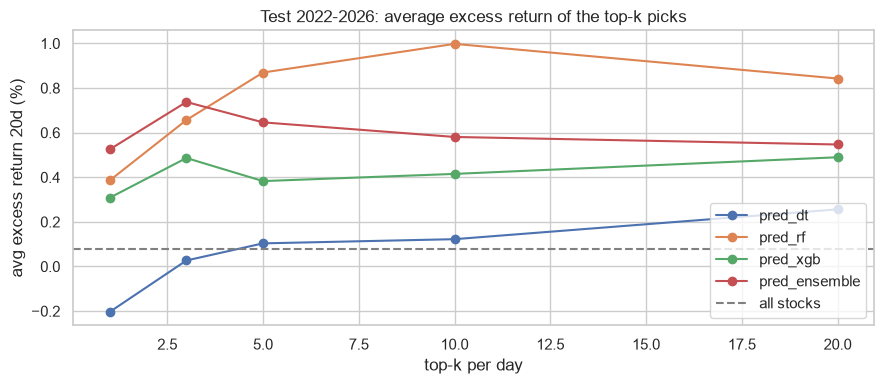

In [6]:
fig, ax = plt.subplots(figsize=(9, 4))
for col in PREDS:
    r = rules[(rules.model == col) & rules.rule.str.startswith("top")]
    ax.plot([int(x.split("-")[1].split()[0]) for x in r.rule], r.avg_excess * 100, marker="o", label=col)
ax.axhline(test["excess_future_20d"].mean() * 100, color="grey", ls="--", label="all stocks")
ax.set_xlabel("top-k per day"); ax.set_ylabel("avg excess return 20d (%)"); ax.legend()
ax.set_title("Test 2022-2026: average excess return of the top-k picks")
plt.tight_layout(); plt.savefig(IMG / "model_topk.png", dpi=110); plt.show()

## 4. Feature importance

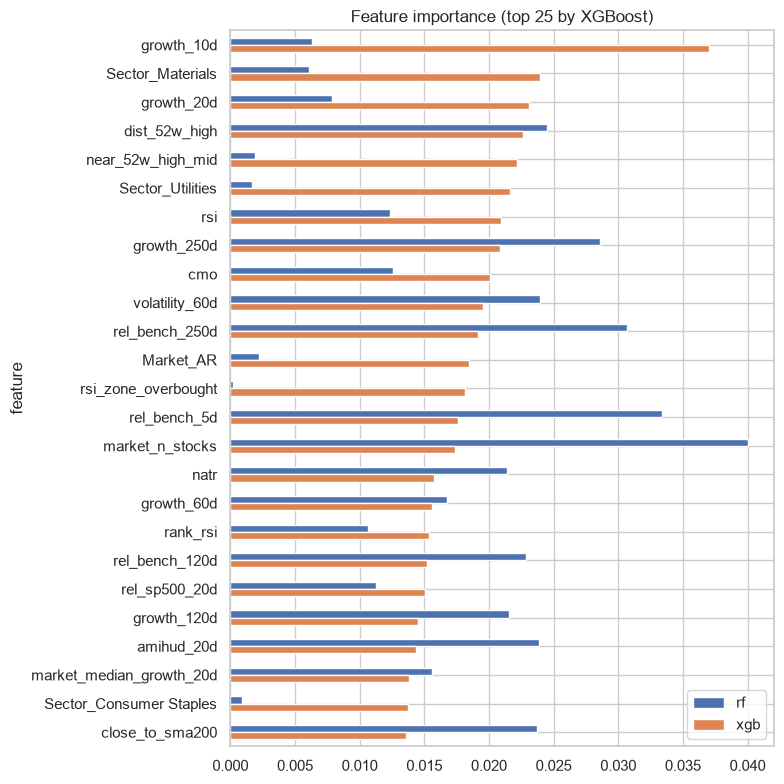

In [7]:
imp = pd.DataFrame({"feature": bundle["features"]})
for fam in ("rf", "xgb"):
    imp[fam] = bundle["models"][fam].feature_importances_
imp = imp.sort_values("xgb", ascending=False)
imp.head(25).set_index("feature").plot.barh(figsize=(8, 8), title="Feature importance (top 25 by XGBoost)").invert_yaxis()
plt.tight_layout(); plt.savefig(IMG / "model_importance.png", dpi=110); plt.show()

## 5. Where does the model work? (precision by market, year, regime)

In [8]:
best = cfg.STRATEGY["prediction"]
top5 = test[test.groupby("Date")[best].rank(ascending=False, method="first") <= 5]
for c in ["Market", "Sector", "market_regime"]:
    t = top5.groupby(c).agg(picks=(TARGET, "size"), precision=(TARGET, "mean"), avg_excess=("excess_future_20d", "mean"))
    t["base_rate"] = test.groupby(c)[TARGET].mean()
    print(t.round(3), "\n")
yearly = top5.groupby(top5["Date"].dt.year).agg(precision=(TARGET, "mean"), avg_excess=("excess_future_20d", "mean"))
yearly["auc_all"] = test.groupby(test["Date"].dt.year).apply(lambda s: roc_auc_score(s[TARGET], s[best]))
yearly.round(3)

        picks  precision  avg_excess  base_rate
Market                                         
AN        209      0.593       0.016      0.535
AR         83      0.639       0.018      0.480
BR       3945      0.492       0.001      0.477
CL        925      0.518       0.006      0.473
MX        948      0.581       0.012      0.491 

                        picks  precision  avg_excess  base_rate
Sector                                                         
Communication             143      0.622       0.013      0.460
Consumer Discretionary    238      0.424       0.000      0.469
Consumer Staples          563      0.483      -0.003      0.447
Energy                    104      0.577       0.018      0.505
Financials               1769      0.581       0.011      0.532
Health Care               115      0.365      -0.034      0.437
Industrials               585      0.528       0.002      0.480
Materials                 792      0.466      -0.003      0.452
Other                 

,precision,avg_excess,auc_all
Date,,,
2022,0.553,0.010,0.569
2023,0.492,0.001,0.505
2024,0.501,0.004,0.539
2025,0.505,0.000,0.490
2026,0.526,0.004,0.530


## 6. Debugging wrong predictions
The worst top-5 picks of the test period (largest negative excess return):

In [9]:
cols = ["Date", "Ticker", "Market", "Sector", best, "excess_future_20d", "growth_future_20d", "rsi", "vix", "market_regime"]
top5.nsmallest(15, "excess_future_20d")[cols].round(3)

,Date,Ticker,Market,Sector,pred_xgb,excess_future_20d,growth_future_20d,rsi,vix,market_regime
67067,2023-03-10,CBAV3.SA,BR,Materials,0.541,-0.343,0.670,21.916000,24.799999,bear
82713,2026-09-15,CMIN3.SA,BR,Materials,0.546,-0.300,0.828,51.078999,17.200001,bear
82714,2026-09-16,CMIN3.SA,BR,Materials,0.552,-0.294,0.816,48.324001,17.709999,bear
99566,2023-10-12,CUERVO.MX,MX,Consumer Staples,0.562,-0.258,0.807,23.256001,16.690001,bear
284684,2025-10-21,SAUD3.SA,BR,Health Care,0.599,-0.227,0.865,53.623001,17.870001,bull
311108,2026-03-06,TGMA3.SA,BR,Industrials,0.535,-0.218,0.844,39.695000,29.490000,bull
307283,2022-05-10,TEND3.SA,BR,Consumer Discretionary,0.543,-0.218,0.914,22.315001,32.990002,bear
284685,2025-10-22,SAUD3.SA,BR,Health Care,0.590,-0.210,0.872,48.806000,18.600000,bull
67578,2025-03-31,CBAV3.SA,BR,Materials,0.571,-0.209,0.837,40.042000,22.280001,bear
76469,2022-05-02,CHILE.SN,CL,Financials,0.536,-0.208,1.016,48.455002,32.340000,bear


In [10]:
# Are the wrong picks concentrated in some tickers?
top5.groupby("Ticker").agg(picks=(TARGET, "size"), precision=(TARGET, "mean"),
                           avg_excess=("excess_future_20d", "mean")).sort_values("picks", ascending=False).head(15).round(3)

,picks,precision,avg_excess
Ticker,,,
ITUB3.SA,284,0.658,0.019
TAEE11.SA,249,0.522,0.002
ALUP11.SA,207,0.396,-0.003
BBSE3.SA,173,0.520,-0.004
EGIE3.SA,157,0.382,-0.008
CPLE3.SA,155,0.516,0.011
ISAE4.SA,146,0.438,-0.010
CBAV3.SA,141,0.489,-0.006
CXSE3.SA,138,0.746,0.042
